In [12]:
#---------------PART A : Data acquisition and understanging----------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier 
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV

from sklearn.metrics import(
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

df=pd.read_csv(r"C:\Users\mabas\Downloads\MCL assignment\archive.zip")
print(df)
print("\nThis is the first 5 rowa of the Dataset:")
print(df.head())
print("\nThis is the shape of dataset :")#which focuses on the amount of columns and rows are present in this dataset
print(df.shape)
print(df.columns)
print("\nThis is the dataset information:") #this displays the information of the dataset
df.info()
print("\nThis describes the datset")
display(df.describe())
print(df.isnull().sum())


       person_age  person_income person_home_ownership  person_emp_length  \
0              22          59000                  RENT              123.0   
1              21           9600                   OWN                5.0   
2              25           9600              MORTGAGE                1.0   
3              23          65500                  RENT                4.0   
4              24          54400                  RENT                8.0   
...           ...            ...                   ...                ...   
32576          57          53000              MORTGAGE                1.0   
32577          54         120000              MORTGAGE                4.0   
32578          65          76000                  RENT                3.0   
32579          56         150000              MORTGAGE                5.0   
32580          66          42000                  RENT                2.0   

           loan_intent loan_grade  loan_amnt  loan_int_rate  loan_status  \

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64


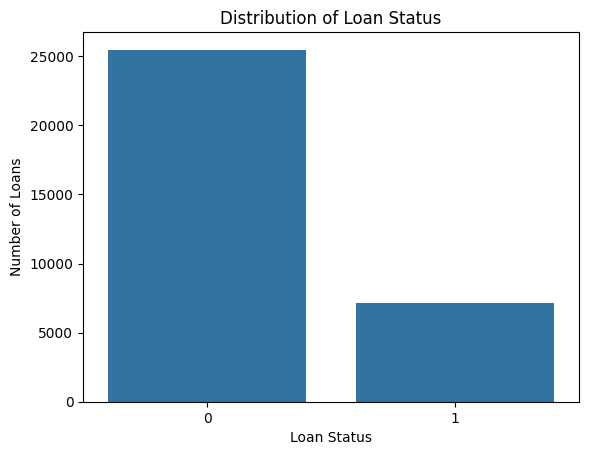

In [13]:
#----------------PART B:Exploratory Data Analysis----------------
#target variable distribution on loan_ststus, it meant to show whether a loan is approved or not.

sns.countplot(x="loan_status",data=df)
plt.title("Distribution of Loan Status")
plt.xlabel("Loan Status")
plt.ylabel("Number of Loans")
plt.show()
#This graph illustartes the number of loans n each loan category, 0 indicates that the loan was not approved  while, 1 indicates that the loan was approved
# This demonstrates that if one category (approved or not approved ) than the other the dataset is imbalanced and it can affect the performance of the model.
#  In this case, we can see that the dataset is imbalanced as there are more loans that were not approved than those that were approved.


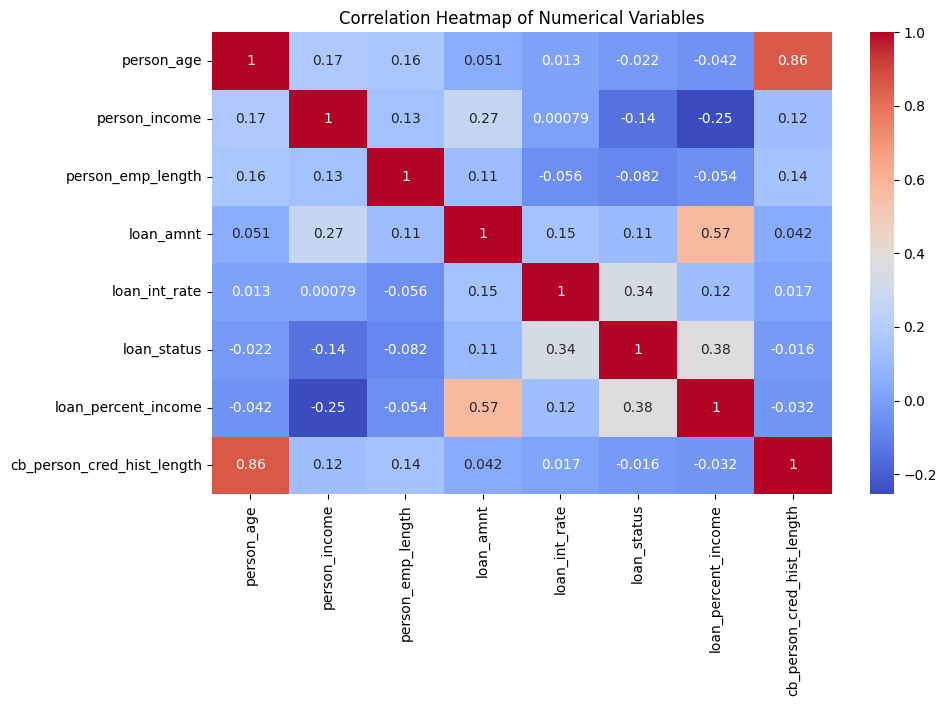

In [14]:
#----------------Heatmap of Correlation Matrix----------------
#This correlation heatmap shows how numerical variables arerelated to one another. The correlation coefficient ranges from -1 to 1,
#  where -1 showsd a strong negative correlation. 0 indicates no correlation, and 1 indicates a strong positive correlation.
numeric_data=df.select_dtypes(include="number")

plt.figure(figsize=(10,6))
sns.heatmap(numeric_data.corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap of Numerical Variables")
plt.show()
# This heatmap shows the stregnth and direction of relationships between the numerical varioables in the dataset.The heatmaps helps identify which variables are positively or negatively correlated with each other, which can be useful for feature selection and model building like loan_status.
#loan amount and loan_period are positively correlated with each other which means that as the loan amount increases, the loan period also can  increase.


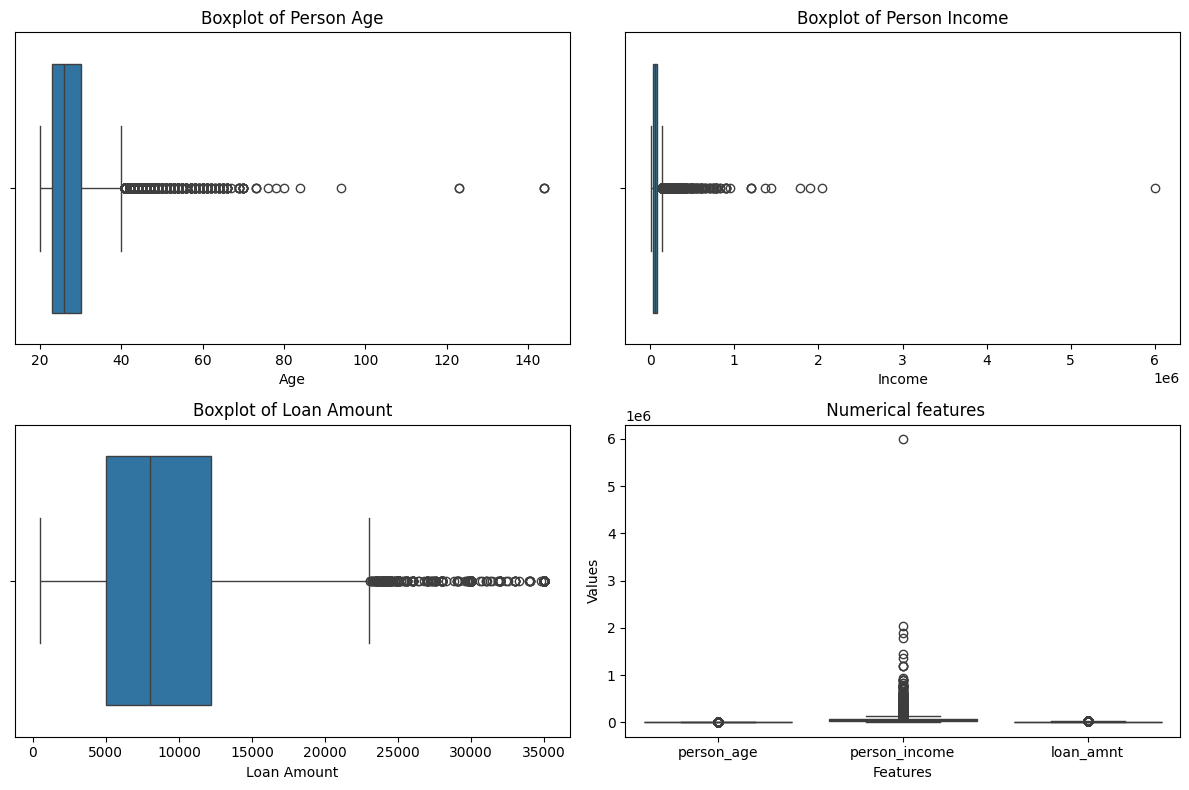

In [15]:
#----------BoxPlot for outliers---------
plt.figure(figsize=(12, 8))

plt.subplot(2,2,1)
sns.boxplot(x=df["person_age"])
plt.title("Boxplot of Person Age")
plt.xlabel("Age")

plt.subplot(2,2,2)
sns.boxplot(x=df["person_income"])
plt.title("Boxplot of Person Income")
plt.xlabel("Income")

plt.subplot(2,2,3)
sns.boxplot(x=df["loan_amnt"])
plt.title("Boxplot of Loan Amount")
plt.xlabel("Loan Amount")

plt.subplot(2,2,4)
sns.boxplot(data=df[["person_age","person_income","loan_amnt"]])
plt.title(" Numerical features")
plt.xlabel("Features")
plt.ylabel("Values")
plt.tight_layout()
plt.show()

#This boxplot shows the spread of numeric features and helps identify outliers outside thw whiskers of the doxplot.
#These outliers can have an impact on the performance of machine learning models,  there are some outliers in the person_income and loan_amnt features, which need to be corrected before building a model.  
#  Outliers can have an impact on the performance of machine learning models,  there are some outliers in the person_income and loan_amnt features, which need to be corrected before building a model.
#i split the boxplot into 4 subplots to show the distribution of a different numeric feature. The first subplot shows the distribution of person_age, the second subplot shows the distribution of person_income, the third subplot shows the distribution of loan_amnt, and the fourth subplot shows a combined boxplot of all three features.

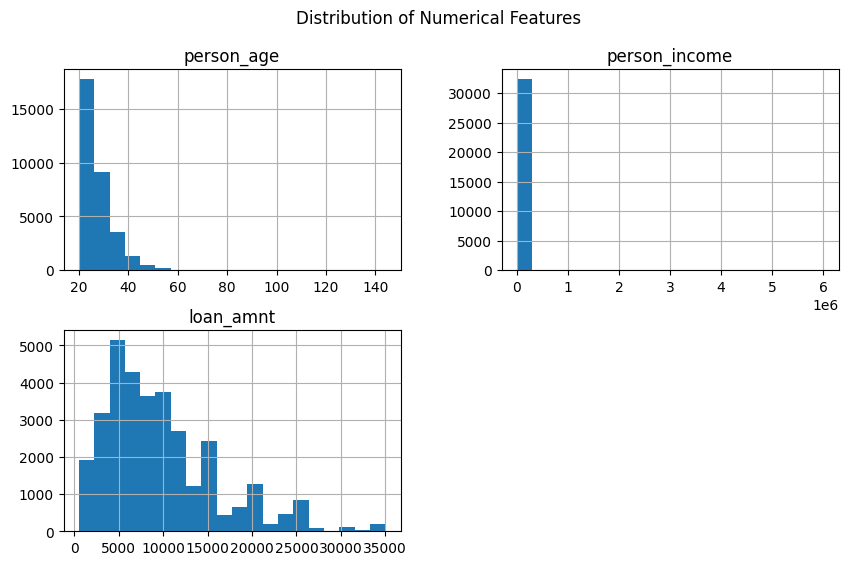

In [16]:
#-----------Histograph for distribution of numerical features----------------
df[["person_age","person_income","loan_amnt"]].hist(bins=20, figsize=(10, 6))
plt.suptitle("Distribution of Numerical Features")
plt.show()



This representation shows how the values are distributed for each numerical feature. The histograms help identify the skewness of the data and can be useful for feature engineering and model building.
It also helps us see whether the data is normally distributed or skewed
Person_income may be right skewed, which means that there are a few individuals with very high incomes that are pulling the mean to the right.
person_age may be left skewed, which means that there are a few individuals with very low ages that are pulling the mean to the left.
loan_amount may be right skewed, which means that there are a few individuals with very high loan amounts that are pulling the mean to the right.

In [17]:
#-----------Part C: Cleaning and Preprocessing------------
print("Missing values before cleaning:")
print(df.isnull().sum())
df=df.dropna()
print("\nThe missing values after remove the rows: ",df.isnull().sum())
print("\nDataset shape after rmoving the missing values: ",df.shape)





Missing values before cleaning:
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

The missing values after remove the rows:  person_age                    0
person_income                 0
person_home_ownership         0
person_emp_length             0
loan_intent                   0
loan_grade                    0
loan_amnt                     0
loan_int_rate                 0
loan_status                   0
loan_percent_income           0
cb_person_default_on_file     0
cb_person_cred_hist_length    0
dtype: int64

Dataset shape after rmoving the missing values:  (28638, 12)


The missing values in the datset can affect the performance of machine learning models. 
Numerical missing values will be replaced with the median because it is less affeceted by  outliers (extreme valuse)
Categorical missing values will be replaced with most frequent category because it is less affected by outliers and can help preserve the distribution of the data.

In [18]:
#-----------Removing duplicates-----------
print("The number of duplicates:")
print(df.duplicated().sum())

df=df.drop_duplicates()
print("Dataset shape after removing duplicates:")
print(df.shape)



The number of duplicates:
137
Dataset shape after removing duplicates:
(28501, 12)


Duplicate records can cause a bias in the model and can lead to overfitting.
 Removing duplicates can make sure that the model is trained on unique data values which can improve its performance.That is why duplicates are dropped

In [19]:
#------------Seperate Features and target variable------------
X= df.drop("loan_status", axis=1)
Y = df["loan_status"]
print("Feature shape:",X.shape)
print("Target shape:", Y.shape)

Feature shape: (28501, 11)
Target shape: (28501,)


In [20]:
#------Removing an ID column------
X= df.drop("loan_status", axis=1)
Y=df["loan_status"]

if "Unnamed: 0" in X.columns:
    X = X.drop("Unnamed: 0", axis=1)
print("ID column checked and removed if still in the dataset")
#-------Split the dataset into training and testing sets-------
# using the 80% for training and 20% for testing
x_train, x_test, y_train, y_test = train_test_split(X, Y, test_size=0.2, random_state=42, stratify=Y) #Stratify helps keeps similar proportions of different  classes in both training and testing sets
print("Training features:", x_train.shape[0])
print("Testing features:", x_test.shape[0])
print("Training target:", y_train.shape[0])
print("Testing target:", y_test.shape[0])



ID column checked and removed if still in the dataset
Training features: 22800
Testing features: 5701
Training target: 22800
Testing target: 5701


The training set is used to train the machine learning model. Testing the set is used to test how well the model performs on unseen data.
An 80/20 spilit gves enough data for training while keeping a seperate part for testing to ensure the model doesnt underfit or overfit.

In [21]:
#-------------Treat Outliers in numerical features-------------
#using IQR to identify and remove outliers in the numerical features of the dataset. 
#  IQR is a measure of statistical scattering,  the difference between the 75th percentile (Q3) and the 25th percentile (Q1) of the data.

numerical_columns= x_train.select_dtypes(include="number").columns
for column in numerical_columns:
    Q1= x_train[column].quantile(0.25)
    Q3=x_train[column].quantile(0.75)

    IQR= Q3-Q1
    lower_limit =Q1- 1.5*IQR
    upper_limit=Q3 + 1.5* IQR

    x_train[column]=x_train[column].clip(
    lower=lower_limit,
    upper=upper_limit
)
    x_test[column]=x_test[column].clip(
        lower=lower_limit,
        upper=upper_limit
    )
print("Outliers have been treated in the numerical features of the dataset using IQR capping.")


Outliers have been treated in the numerical features of the dataset using IQR capping.


IQR method identifies unuasally high or low observations based on the distance between 1rst and 3rd quartile
By capping and not deleting observations, capping replaces extreme values with the lower upper boundary. Which allows us to kep the observation instead of losing useful loan records

In [22]:
#---------------Encoding categorical Variables------------------------------
x_train= pd.get_dummies(x_train, drop_first=True) #This removes one category from each categorical variable to avoid redundancy
x_test= pd.get_dummies(x_test, drop_first=True)

x_train,x_test=x_train.align(x_test, join="left", axis=1, fill_value=0)

print("Categorical variables encoded")
print("Training shape after encoding:", x_train.shape)
print("Testing shape after encoding:", x_test.shape)

Categorical variables encoded
Training shape after encoding: (22800, 22)
Testing shape after encoding: (5701, 22)


In [23]:
#-------feature scaling----------------------------------

scaler = StandardScaler() #Used to standardise features ,scaling to unit variance
x_train_scaled= scaler.fit_transform(x_train)
x_test_scaled= scaler.transform(x_test)
print("This is feature scaling complete:", x_train_scaled, x_test_scaled)
print("The shape of scaled training data: ",x_train_scaled.shape)
print("Shape of scaled testing data: ",x_test_scaled.shape)

This is feature scaling complete: [[ 1.83143099  0.66201202  1.67669354 ... -0.08537913 -0.04781125
   2.14233641]
 [-1.22659838 -0.91515085  0.07997039 ... -0.08537913 -0.04781125
  -0.4667801 ]
 [-0.65321787 -0.56817502 -1.25063224 ... -0.08537913 -0.04781125
   2.14233641]
 ...
 [ 0.11128947 -0.56817502  0.07997039 ... -0.08537913 -0.04781125
   2.14233641]
 [ 0.49354314 -0.72589131  1.14445249 ... -0.08537913 -0.04781125
  -0.4667801 ]
 [ 1.64030415 -1.19904017 -1.25063224 ... -0.08537913 -0.04781125
  -0.4667801 ]] [[ 2.02255782  2.4473604   2.60811538 ... -0.08537913 -0.04781125
  -0.4667801 ]
 [ 1.83143099  0.69355528  2.60811538 ... -0.08537913 -0.04781125
  -0.4667801 ]
 [-0.65321787 -1.0099068   0.61221144 ... -0.08537913 -0.04781125
   2.14233641]
 ...
 [-0.07983737 -1.00978063 -1.25063224 ... -0.08537913 -0.04781125
  -0.4667801 ]
 [ 2.50037491 -0.75743457 -0.71839119 ... -0.08537913 -0.04781125
  -0.4667801 ]
 [ 2.50037491  2.4473604   0.07997039 ... -0.08537913 -0.0478112

The importance of scaling:
Feature scaling is defind as " a preprocessing step that transforms features to a similar scale, ensuring all variables contribute equally to a model"(geeksforgeeks)
Feature scaling is important becasue numericale features can have different ranges and units. Feature scaling is important for distance-based algorithms such as K-nearest neighbours.
StandardScaler puts the numerical feartures on a similar scale this makes sure features with large values from having too much influence on a machine learning model.

PCA has been applied to the scaled training data
First number of features: 22
Number of first principal components: 22

Explained variance ratio: 
PC 1 : 0.1055
PC 2 : 0.0964
PC 3 : 0.0756
PC 4 : 0.0709
PC 5 : 0.0576
PC 6 : 0.0556
PC 7 : 0.0549
PC 8 : 0.0539
PC 9 : 0.0517
PC 10 : 0.05
PC 11 : 0.0476
PC 12 : 0.0462
PC 13 : 0.046
PC 14 : 0.045
PC 15 : 0.0409
PC 16 : 0.0375
PC 17 : 0.025
PC 18 : 0.0208
PC 19 : 0.0086
PC 20 : 0.0057
PC 21 : 0.0033
PC 22 : 0.0014

Cumualative explained variance: 
PC 1 : 0.1055
PC 2 : 0.2018
PC 3 : 0.2774
PC 4 : 0.3483
PC 5 : 0.4059
PC 6 : 0.4615
PC 7 : 0.5163
PC 8 : 0.5702
PC 9 : 0.622
PC 10 : 0.672
PC 11 : 0.7196
PC 12 : 0.7658
PC 13 : 0.8118
PC 14 : 0.8568
PC 15 : 0.8977
PC 16 : 0.9352
PC 17 : 0.9602
PC 18 : 0.981
PC 19 : 0.9896
PC 20 : 0.9953
PC 21 : 0.9986
PC 22 : 1.0


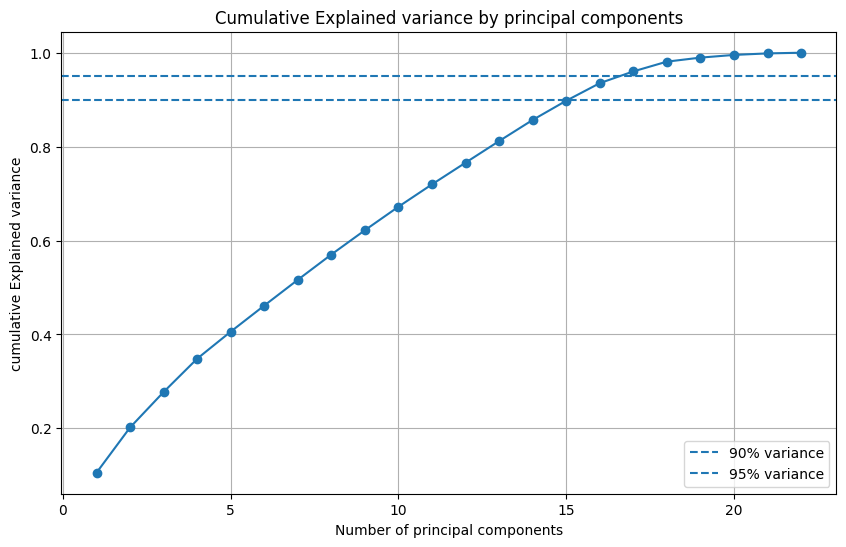


Components needed for 90% variance:  16
Components needed for 95% variance: 17

PCA-transformed training data  shape: (22800, 16)
PCA-transformed testing data shape:  (5701, 16)

Total variance retained: 0.9352
Percentage of variance retained: 93.52 %

NaN values in traing data: 0
NaN values in testing data:  0


In [24]:
#-----------Principal Components analysis(PCA)------------------------------
pca = PCA() #Placing PCA to the scaled training data, creating a pca model
x_train_pca = pca.fit_transform(x_train_scaled)

print("PCA has been applied to the scaled training data")
print("First number of features:",x_train_scaled.shape[1])
print("Number of first principal components:",x_train_pca.shape[1])

#explained variance ratio
explained_variance= pca.explained_variance_ratio_
print("\nExplained variance ratio: ")
for i,variance in enumerate(explained_variance):
    print("PC", i+1,":",round(variance, 4))

#calculating and plottig cummulative variance
cumulative_variance= np.cumsum(explained_variance)

print("\nCumualative explained variance: ")
for i, variance in enumerate(cumulative_variance):
    print("PC", i+1,":",round(variance, 4))

#plotting cummulative variance
plt.figure(figsize=(10,6))
plt.plot(
    range(1, len(cumulative_variance)+1),
    cumulative_variance,
    marker="o"
)
plt.axhline(y=0.90, linestyle="--",label="90% variance")
plt.axhline(y=0.95,linestyle="--",label="95% variance")
plt.xlabel("Number of principal components")
plt.ylabel("cumulative Explained variance")
plt.title("Cumulative Explained variance by principal components")
plt.legend()
plt.grid()
plt.show()

#select components  capturing at least 90–95% variance
components_90 =np.argmax(cumulative_variance >=0.90)+1
components_95 = np.argmax(cumulative_variance >=0.95)+1

print("\nComponents needed for 90% variance: ",components_90)
print("Components needed for 95% variance:",components_95)

#creating PCA-transformed dataset
number_of_components=components_90
pca_final= PCA(n_components= number_of_components)
x_train_pca= pca_final.fit_transform(x_train_scaled)
x_test_pca= pca_final.transform(x_test_scaled)

print("\nPCA-transformed training data  shape:",x_train_pca.shape)
print("PCA-transformed testing data shape: ",x_test_pca.shape)

total_variance= sum(pca_final.explained_variance_ratio_)
print("\nTotal variance retained:", round(total_variance,4))
print("Percentage of variance retained:", round(total_variance * 100,2), "%")

#cheching for NaN values in training data, this s to ensure that PCA will run without producing an error
print("\nNaN values in traing data:",np.isnan(x_train_scaled).sum())
print("NaN values in testing data: ",np.isnan(x_test_scaled).sum())



This chart shows the level of variance preserved when additional principal components are added.
The x-axis represents the number of components used while Y-ais shows the percentage of cumulative explained varaince.
As the number of components increase the percentage of variance preserved will increase as well.This chart provides an indication of  the number of principal components required while preserving  the majority of the information in the dataset.
The 90% and 95% curves represents the level of variance that needs to be kept. This p;rovides us with an indication about the number of components which will help to preserve atleast 90% or 95% variance

In [25]:
#----------------Part E: Model Development(before and after pca)--------------------------

#logistic regression this is for berfore pca
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(x_train_scaled, y_train)
logistic_pred =logistic_model.predict(x_test_scaled)
#k-nearest neighbours
knn_model= KNeighborsClassifier()
knn_model.fit(x_train_scaled, y_train)
knn_pred =knn_model.predict(x_test_scaled)
#decision tree classifier
tree_model= DecisionTreeClassifier(random_state=42)
tree_model.fit(x_train_scaled, y_train)
tree_pred = tree_model.predict(x_test_scaled)

#logistic predictions this is for after pca
logistic_pca_model =LogisticRegression(max_iter=1000)
logistic_pca_model.fit(x_train_pca, y_train)
logistic_pca_pred =logistic_pca_model.predict(x_test_pca)

knn_pca_model= KNeighborsClassifier()
knn_pca_model.fit(x_train_pca, y_train)
knn_pca_pred= knn_pca_model.predict(x_test_pca)

tree_pca_model= DecisionTreeClassifier(random_state=42)
tree_pca_model.fit(x_train_pca, y_train)
tree_pca_pred= tree_pca_model.predict(x_test_pca)
#Evaluating the original feature model
print("\n==========Logistic Regression===================")
#COMPARING ALL MODELS
allmodels ={
    "Logistic Regression": logistic_pred,
    "KNN":knn_pred,
    "Decision tree":tree_pred,
    "Logistic Regression PCA": logistic_pca_pred,
    "KNN PCA":knn_pca_pred,
    "Decision tree PCA":tree_pca_pred
}
results =[]
for name, prediction in allmodels.items():
    print("\n========================")
    print(name)
    print("\n===========================")
    accuracy=accuracy_score(y_test, prediction)
    precision=precision_score(y_test, prediction, average="weighted",zero_division=0)
    recall=recall_score(y_test, prediction, average="weighted",zero_division=0)
    f1=f1_score(y_test, prediction, average="weighted",zero_division=0)

    print("Accuracy:",round(accuracy,4))
    print("Precision:",round(precision,4))
    print("Recall:", round(recall,4))
    print("f1-score:",round(f1, 4))

    print("Confussion Matrix: ")
    print(confusion_matrix(y_test, prediction))

    print("Classification Report: ")
    print(classification_report(y_test, prediction, zero_division=0))

    results.append({
    "Model":name,
    "Accuracy":accuracy,
    "Precision":precision,
    "Recall": recall,
    "f1_Score":f1
})


#Training the model using pca features

#turning these results into a table
results_df=pd.DataFrame(results)
print("\n=======================Final Model Comparison===========================")
print(results_df.round(4))



==========Logistic Regression===================

Logistic Regression

Accuracy: 0.8613
Precision: 0.8533
Recall: 0.8613
f1-score: 0.8531
Confussion Matrix: 
[[4231  232]
 [ 559  679]]
Classification Report: 
              precision    recall  f1-score   support

           0       0.88      0.95      0.91      4463
           1       0.75      0.55      0.63      1238

    accuracy                           0.86      5701
   macro avg       0.81      0.75      0.77      5701
weighted avg       0.85      0.86      0.85      5701


KNN

Accuracy: 0.8918
Precision: 0.8888
Recall: 0.8918
f1-score: 0.8848
Confussion Matrix: 
[[4332  131]
 [ 486  752]]
Classification Report: 
              precision    recall  f1-score   support

           0       0.90      0.97      0.93      4463
           1       0.85      0.61      0.71      1238

    accuracy                           0.89      5701
   macro avg       0.88      0.79      0.82      5701
weighted avg       0.89      0.89      0.88    

Logistic Regression
This is a supervised ml algorithm .This predicts the categorical outcome being the loan_status of clients loan applicants.This model was trained using preprocessed trained data then tested using testing dataand evaluated using accuracy, precision, recall and f1-score

Best model that was selected: decision tree

========== Grid Search Reslts =============
Best parameter: {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 2}

Cross-Validation F1-Score:
0.9214

========Tuned Model Results========
Accuracy: 0.924
Precesion: 0.9257
Recall: 0.924
f1Score: 0.9194

Confusion Matrix: [[4416   47]
 [ 386  852]]

Classification Report:               precision    recall  f1-score   support

           0       0.92      0.99      0.95      4463
           1       0.95      0.69      0.80      1238

    accuracy                           0.92      5701
   macro avg       0.93      0.84      0.88      5701
weighted avg       0.93      0.92      0.92      5701



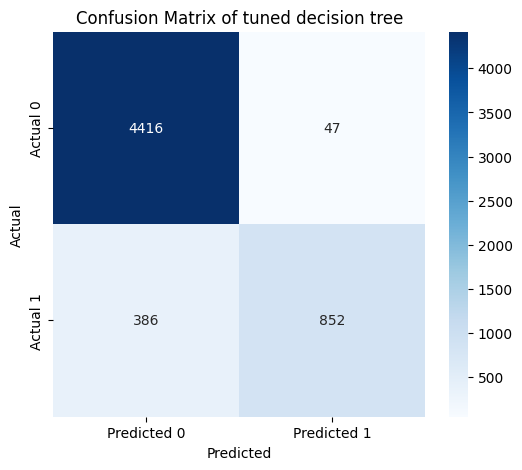

In [26]:
#---------------------------MODE OPTIMSATION------------------
#seleting the best peforming model
best_model= DecisionTreeClassifier(random_state=42)
print("Best model that was selected: decision tree")
#creating a aparameter grid for the decision tree
parameter_grid={
    "max_depth":[3,5,7,10,None],
    "min_samples_split":[2,5,10],
    "min_samples_leaf":[1,2,4],
    "criterion":["gini","entropy"]
}
#applying GridSearchCV
grid_search =GridSearchCV(
    estimator= best_model,
    param_grid=parameter_grid,
    cv =5,
    scoring="f1_weighted",#loan_status target is imbalanced thereforusing ony the accuracy is nt ial 
    n_jobs=-1
)
grid_search.fit(x_train_scaled, y_train)

print("\n========== Grid Search Reslts =============")
print("Best parameter:", grid_search.best_params_)
print("\nCross-Validation F1-Score:")
print(round(grid_search.best_score_, 4))
#Evaluating the tuned model
tuned_model =grid_search.best_estimator_
tuned_pred=tuned_model.predict(x_test_scaled)
tuned_accuracy =accuracy_score(y_test, tuned_pred)
tuned_precision=precision_score(y_test, tuned_pred,average="weighted",zero_division=0)
tuned_recall=recall_score(y_test,tuned_pred,average="weighted",zero_division=0)
tuned_f1= f1_score(y_test,tuned_pred, average="weighted",zero_division=0)

print("\n========Tuned Model Results========")
print("Accuracy:",round(tuned_accuracy,4))
print("Precesion:",round(tuned_precision,4))
print("Recall:",round(tuned_recall, 4))
print("f1Score:",round(tuned_f1, 4))

print("\nConfusion Matrix:",confusion_matrix(y_test, tuned_pred))
print("\nClassification Report:",classification_report(y_test, tuned_pred, zero_division=0))

cm= confusion_matrix(y_test, tuned_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm,annot=True, fmt="d",cmap="Blues", xticklabels=["Predicted 0","Predicted 1"],
            yticklabels=["Actual 0", "Actual 1"]
            )
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix of tuned decision tree")
plt.show() 

In [27]:
#comparing the results before and after tuning
comparison =pd.DataFrame({
    "Metric":["Accuracy","Precision","Recall","f1-Score"],
    "Before Tuning":[accuracy_score(y_test, tree_pred),
                     precision_score(y_test, tree_pred, average="weighted", zero_division=0),
                     recall_score(y_test,tree_pred,average="weighted",zero_division=0),
                     f1_score(y_test, tree_pred, average="weighted",zero_division=0)
                     ],
                     "After Tuning":[
                         tuned_accuracy,
                         tuned_precision,
                         tuned_recall,
                         tuned_f1
                     ]
})
print("\n===============Before vs After Tuning=========================")
print(comparison.round(4))



===============Before vs After Tuning=========================
      Metric  Before Tuning  After Tuning
0   Accuracy         0.8832        0.9240
1  Precision         0.8860        0.9257
2     Recall         0.8832        0.9240
3   f1-Score         0.8844        0.9194


The impact on bias and variance 
High bias happened when the model is too simple and cant learn the patterns in data which can lead to underfitting. A decision tree is too simple which leads t high bias because it cant capture enough relationships in data.
A high variance happens when a model is too complex and ends up learning the trained data too closely which leads to overfitting.Decision tree, a complex decision tree can have a high variance because it learns everypattern from the training data.
GridSearchCV tries different combinations of hyperparameters and uses cross-validation in order to determine which one works best.
Tuning will help keep complexity of our model within limits, if a model is too simple it might suffer from high bias leading to underfitting. If it is very complex, it will be subjected to high variance and hence will suffer from overfitting